# Training a pCTR model on Taobao

**Question:** before showing an ad, how likely is it to receive a click?
Each impression is an observation, `clk ∈ {0, 1}` is the label, and pCTR estimates
$P(clk=1\mid x)$. We are predicting clicks, not conversions or the causal effect of showing an ad.

We reuse the three CSV files and left joins from notebook 01. First run
`python download_data.py` from the repository root. You do not need to run the first notebook.
The Alibaba/Tianchi data is licensed under CC BY-NC-SA 4.0 (see README).

We will work through sampling, a temporal split, features, a baseline and models, thresholds,
calibration, and segments. We compare models primarily by **validation log loss**:
we want useful probabilities.

In [1]:
from pathlib import Path
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, log_loss, precision_recall_curve,
    roc_curve, brier_score_loss)
from sklearn.calibration import calibration_curve
import sklearn

SEED = 42
SAMPLE_FRACTION = 0.05  # 1.0 uses all rows; 0.01 reduces memory further
CHUNK_SIZE = 500_000
RUN_LIGHTGBM = True
DATA_DIR = Path('../data/taobao')
assert 0 < SAMPLE_FRACTION <= 1
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.grid': True})
pd.set_option('display.max_columns', 20)
print('pandas', pd.__version__, '| sklearn', sklearn.__version__)
print('Seed:', SEED, '| fraction of impressions:', SAMPLE_FRACTION)

pandas 2.2.3 | sklearn 1.8.0
Seed: 42 | fraction of impressions: 0.05


## 1. Sampling without changing the problem
We read the CSV in chunks so we do not have to load 26.6 million rows before sampling.
Each impression has the same probability of being kept, **regardless of its label**.
We use the same rule in all three periods: we neither equalize the classes nor undersample negatives.
The evaluation CTR may differ slightly from 5.14% because of sampling variation and changes over time.

This sample does not preserve every event for each user or the blocks of three ads.
It is useful for comparing simple models, but not for reconstructing complete histories.
Whether a user or ad appears in training depends on sampling, so “new in test” means new **in this sample**.
Reproducing it requires CSV files with the same checksums and row order.

In [2]:
rng = np.random.default_rng(SEED)
parts = []
source_rows = 0
for chunk in pd.read_csv(DATA_DIR / 'raw_sample.csv', chunksize=CHUNK_SIZE,
        dtype={'user': 'int32', 'adgroup_id': 'int32', 'pid': 'category',
               'clk': 'int8', 'nonclk': 'int8'}):
    source_rows += len(chunk)
    keep = rng.random(len(chunk)) < SAMPLE_FRACTION
    parts.append(chunk.loc[keep].copy())
impressions = pd.concat(parts, ignore_index=True)
del parts, chunk
assert impressions['clk'].isin([0, 1]).all()
assert (impressions['clk'] + impressions['nonclk']).eq(1).all()
impressions = impressions.drop(columns='nonclk')
ads = pd.read_csv(DATA_DIR / 'ad_feature.csv')
users = pd.read_csv(DATA_DIR / 'user_profile.csv')
users.columns = users.columns.str.strip()  # trailing space found in notebook 01
assert ads['adgroup_id'].is_unique and users['userid'].is_unique
print(f'Original rows: {source_rows:,}; sample: {len(impressions):,}')
display(pd.DataFrame({'table': ['impressions', 'ads', 'users'],
                     'rows': [len(impressions), len(ads), len(users)]}))
print('Actual columns:', {'ads': list(ads), 'users': list(users)})

Original rows: 26,557,961; sample: 1,327,227


,table,rows
0,impressions,1327227
1,ads,846811
2,users,1061768


Actual columns: {'ads': ['adgroup_id', 'cate_id', 'campaign_id', 'customer', 'brand', 'price'], 'users': ['userid', 'cms_segid', 'cms_group_id', 'final_gender_code', 'age_level', 'pvalue_level', 'shopping_level', 'occupation', 'new_user_class_level']}


## 2. Preparation and temporal split
- **Train:** May 6–10. Fit transformations and model parameters.
- **Validation:** May 11–12. Choose regularization, boosting iterations, and thresholds.
- **Test:** May 13. Evaluate the final models without using the results to choose parameters.

All times are interpreted in `Asia/Shanghai`. Unlike the official May 6–12/13 split,
we reserve two training days for validation. We do not refit after selecting models,
so the probabilities remain consistent with the thresholds chosen on validation data.

In [3]:
user_cols = [c for c in users if c != 'userid']
users = users.astype(dict.fromkeys(user_cols, 'Int8'))
ads = ads.astype({'cate_id': 'int32', 'campaign_id': 'int32', 'customer': 'int32', 'brand': 'Int32'})
df = (impressions.merge(users, left_on='user', right_on='userid', how='left', validate='many_to_one')
      .drop(columns='userid').merge(ads, on='adgroup_id', how='left', validate='many_to_one'))
assert len(df) == len(impressions)
assert df['cate_id'].notna().all()
del impressions, ads, users
shown_at = pd.to_datetime(df['time_stamp'], unit='s', utc=True).dt.tz_convert('Asia/Shanghai')
assert shown_at.min() >= pd.Timestamp('2017-05-06', tz='Asia/Shanghai')
assert shown_at.max() < pd.Timestamp('2017-05-14', tz='Asia/Shanghai')
df['day'] = shown_at.dt.day.astype('int8')
df['hour'] = shown_at.dt.hour.astype('int8')
assert not df.duplicated(['user', 'adgroup_id', 'time_stamp']).any()
masks = {'train': df.day.between(6, 10), 'valid': df.day.between(11, 12), 'test': df.day.eq(13)}
assert sum(m.astype(int) for m in masks.values()).eq(1).all()
summary = pd.DataFrame({name: {'impressions': int(m.sum()), 'clicks': int(df.loc[m, 'clk'].sum()),
    'CTR': df.loc[m, 'clk'].mean(), 'start': shown_at[m].min(), 'end': shown_at[m].max()}
    for name, m in masks.items()}).T
display(summary)
print(f'Joined table memory: {df.memory_usage(deep=True).sum()/1e6:.1f} MB')
print(f'Full sample CTR: {df.clk.mean():.2%}; accuracy when always predicting 0: {1-df.clk.mean():.2%}')

,impressions,clicks,CTR,start,end
train,831179,43198,0.051972,2017-05-06 00:00:00+08:00,2017-05-10 23:59:46+08:00
valid,330705,16803,0.05081,2017-05-11 00:00:00+08:00,2017-05-12 23:59:47+08:00
test,165343,8264,0.049981,2017-05-13 00:00:01+08:00,2017-05-13 23:59:44+08:00


Joined table memory: 81.0 MB
Full sample CTR: 5.14%; accuracy when always predicting 0: 94.86%


## 3. What is available before an impression?
| Variables | Decision |
|---|---|
| `pid`, hour | Placement and time are known when serving an ad. Treat hour as categorical rather than assuming a linear effect. |
| User attributes | Categories, including age brackets and levels. Missing values get an explicit category. |
| `cate_id`, price, missing brand | Candidate metadata; apply a logarithm to price and learn a clipping limit from training data. |
| `user`, `adgroup_id`, campaign, advertiser, brand ID | Excluded to control cardinality and avoid memorizing IDs in this introduction. Use IDs only for segment diagnostics. |
| `clk`, `nonclk` | The label and its complement: **never features**. |
| Per-ad or per-user CTR computed on the full dataset | Direct leakage from the future and the observation's own label. Not used. |
| Day and absolute timestamp | Used only for splitting and checks, not as features here. |

**A temporal limitation of the dataset:** profiles and metadata are snapshots without effective dates.
We cannot establish that they had these values before each impression. We assume they were available
for this experiment; an operational evaluation would require historical point-in-time joins.

We do not use target encoding, balance classes, or set `class_weight='balanced'`:
the latter changes the objective and can distort pCTR. Infrequent and unknown categories
are handled by an encoder fitted exclusively on training data.

In [4]:
cat_cols = ['pid', 'hour', 'cate_id'] + user_cols
num_cols = ['log_price', 'brand_missing', 'profile_missing']
price_cap = df.loc[masks['train'], 'price'].quantile(0.995)
price_fill = df.loc[masks['train'], 'price'].median()
X = df[cat_cols].astype('string').fillna('missing')
X['log_price'] = np.log1p(df['price'].fillna(price_fill).clip(0, price_cap)).astype('float32')
X['brand_missing'] = df['brand'].isna().astype('float32')
X['profile_missing'] = df['cms_group_id'].isna().astype('float32')
assert not set(['clk', 'nonclk', 'day', 'user', 'adgroup_id', 'time_stamp']) & set(X.columns)
preprocessor = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=0.001,
                          max_categories=128, dtype=np.float32), cat_cols),
    ('num', StandardScaler(), num_cols),
], sparse_threshold=1.0)
Xt = {'train': preprocessor.fit_transform(X.loc[masks['train']])}
for name in ['valid', 'test']:
    Xt[name] = preprocessor.transform(X.loc[masks[name]])
y = {name: df.loc[m, 'clk'].to_numpy() for name, m in masks.items()}
assert all(np.unique(a).size == 2 for a in y.values())
for name, matrix in Xt.items():
    print(name, matrix.shape, f'{(matrix.data.nbytes+matrix.indices.nbytes+matrix.indptr.nbytes)/1e6:.1f} MB sparse')
print(f'Price clipping limit learned on train: {price_cap:,.2f}')
del X

train (831179, 252) 96.4 MB sparse
valid (330705, 252) 38.4 MB sparse
test (165343, 252) 19.2 MB sparse
Price clipping limit learned on train: 9,140.00


## 4. Baseline and models
The baseline predicts the **training CTR** for every impression. At a threshold of 0.5,
it is almost 95% accurate but detects no clicks. It is a useful reference for log loss.

Logistic regression learns additive effects on log-odds; we use one-hot encoding and L2 regularization.
We try just two values of `C` (smaller C means stronger regularization). LightGBM can learn nonlinear
interactions. To keep the comparison easy to follow, it uses the same sparse matrix; this is not
an exhaustive optimization and does not use native categorical features. We limit trees, leaves,
and computation to four threads.

Test data does not participate in selection. LightGBM is optional: set `RUN_LIGHTGBM=False` to skip it.

In [5]:
train_ctr = float(y['train'].mean())
valid_prob = {'Constant': np.full(len(y['valid']), train_ctr)}
models = {}
trials = []
for C in [0.1, 1.0]:
    start = time.perf_counter()
    model = LogisticRegression(C=C, solver='lbfgs', max_iter=400, tol=1e-5, random_state=SEED)
    with warnings.catch_warnings():
        warnings.simplefilter('error', ConvergenceWarning)
        model.fit(Xt['train'], y['train'])
    p = model.predict_proba(Xt['valid'])[:, 1]
    trials.append({'C': C, 'valid_logloss': log_loss(y['valid'], p),
                   'seconds': time.perf_counter()-start, 'iterations': int(model.n_iter_[0])})
    if 'Logistic regression' not in models or trials[-1]['valid_logloss'] < log_loss(y['valid'], valid_prob['Logistic regression']):
        models['Logistic regression'] = model
        valid_prob['Logistic regression'] = p
display(pd.DataFrame(trials))
if RUN_LIGHTGBM:
    import lightgbm as lgb
    print('LightGBM', lgb.__version__)
    start = time.perf_counter()
    model = lgb.LGBMClassifier(n_estimators=250, learning_rate=0.05, num_leaves=15,
        min_child_samples=200, reg_lambda=5, n_jobs=4, random_state=SEED,
        deterministic=True, force_col_wise=True, verbosity=-1)
    model.fit(Xt['train'], y['train'], eval_set=[(Xt['valid'], y['valid'])],
              eval_metric='binary_logloss', callbacks=[lgb.early_stopping(25, verbose=False)])
    models['LightGBM'] = model
    valid_prob['LightGBM'] = model.predict_proba(Xt['valid'])[:, 1]
    print('Selected trees:', model.best_iteration_, '| seconds:', round(time.perf_counter()-start, 1))
validation = pd.DataFrame({name: {'logloss': log_loss(y['valid'], p),
    'ROC-AUC': roc_auc_score(y['valid'], p), 'AP': average_precision_score(y['valid'], p)}
    for name, p in valid_prob.items()}).T
best_name = validation['logloss'].idxmin()
display(validation)
print('Model selected by validation log loss:', best_name)

,C,valid_logloss,seconds,iterations
0,0.1,0.200354,2.665276,101
1,1.0,0.200378,2.574675,93


LightGBM 4.6.0


/workspace/ads-data-course/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Selected trees: 157 | seconds: 4.7


,logloss,ROC-AUC,AP
Constant,0.200906,0.500000,0.050810
Logistic regression,0.200354,0.543996,0.058282
LightGBM,0.200180,0.548155,0.060360


Model selected by validation log loss: LightGBM


## 5. Probability versus decision: choosing a threshold
Accuracy, precision, recall, and F1 require a binary decision. ROC-AUC measures ranking;
PR-AUC emphasizes performance on the positive class; log loss penalizes incorrect probabilities,
especially confident ones. Here we report **average precision (AP)** as the PR-AUC summary,
rather than trapezoidal area under the PR curve. Its constant-score reference is click prevalence.

For each model, we choose a threshold that maximizes F1 **on validation data only**.
This illustrates the tradeoff: in ads, a real decision threshold depends on costs, value,
and constraints; F1 does not measure profitability. A pCTR score can also feed a ranking
or a bid without being converted to a binary prediction.

,F1 threshold selected on validation
Constant,0.051972
Logistic regression,0.052951
LightGBM,0.054712


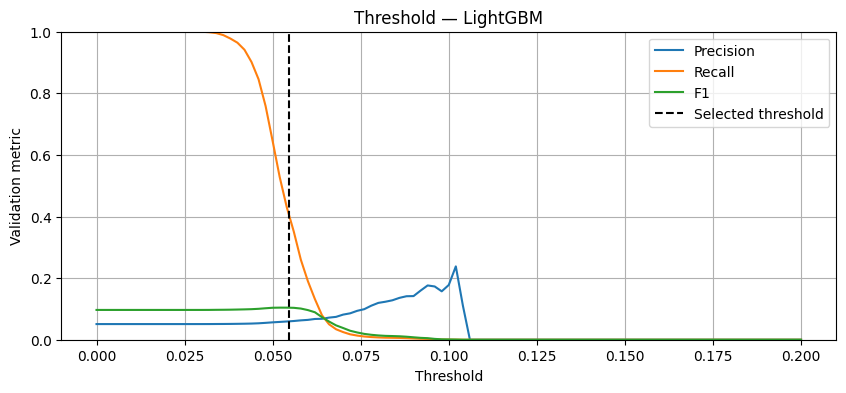

In [6]:
thresholds = {}
for name, p in valid_prob.items():
    precision, recall, ts = precision_recall_curve(y['valid'], p)
    scores = 2*precision[:-1]*recall[:-1] / np.maximum(precision[:-1]+recall[:-1], 1e-15)
    thresholds[name] = float(ts[np.argmax(scores)])
display(pd.Series(thresholds, name='F1 threshold selected on validation').to_frame())
grid = np.linspace(0, 0.20, 101)
p = valid_prob[best_name]
fig, ax = plt.subplots()
for label, metric in [('Precision', precision_score), ('Recall', recall_score), ('F1', f1_score)]:
    ax.plot(grid, [metric(y['valid'], p >= t, zero_division=0) for t in grid], label=label)
ax.axvline(thresholds[best_name], color='black', ls='--', label='Selected threshold')
ax.set(xlabel='Threshold', ylabel='Validation metric', ylim=(0, 1), title=f'Threshold — {best_name}')
ax.legend(); plt.show()

## 6. Final evaluation on the held-out day
We freeze models and thresholds before evaluating test data. We show both 0.5 and the threshold
chosen on validation data. Probability metrics do not change with the threshold.
We will not retune models based on this table: doing so would turn test into another validation set.

/workspace/ads-data-course/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


threshold  accuracy  precision   recall  \
model               rule                                                
Constant            0.5         0.50000   0.95002    0.00000  0.00000   
                    F1 valid    0.05197   0.04998    0.04998  1.00000   
Logistic regression 0.5         0.50000   0.95002    0.00000  0.00000   
                    F1 valid    0.05295   0.53339    0.05708  0.53715   
LightGBM            0.5         0.50000   0.95002    0.00000  0.00000   
                    F1 valid    0.05471   0.64324    0.05921  0.41227   

                                   F1  ROC-AUC  PR-AUC (AP)  logloss  \
model               rule                                               
Constant            0.5       0.00000  0.50000      0.04998  0.19850   
                    F1 valid  0.09520  0.50000      0.04998  0.19850   
Logistic regression 0.5       0.00000  0.54823      0.05848  0.19785   
                    F1 valid  0.10320  0.54823      0.05848  0.19785   
LightGBM            0.5       0.00000  0.54721      0.05860  0.19787   
                    F1 valid  0.10355  0.54721      0.05860  0.19787   

                              predicted positive fraction  
model               rule                                   
Constant            0.5                           0.00000  
                    F1 valid                      1.00000  
Logistic regression 0.5                           0.00000  
                    F1 valid                      0.47032  
LightGBM            0.5                           0.00000  
                    F1 valid                      0.34799

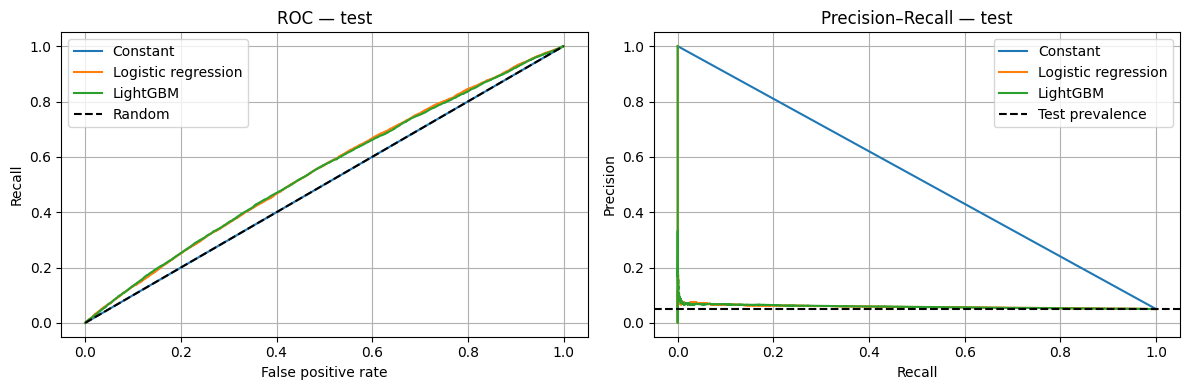

In [7]:
test_prob = {'Constant': np.full(len(y['test']), train_ctr)}
for name, model in models.items():
    test_prob[name] = model.predict_proba(Xt['test'])[:, 1]

def metrics(target, p, threshold):
    pred = p >= threshold
    return {'accuracy': accuracy_score(target, pred),
        'precision': precision_score(target, pred, zero_division=0),
        'recall': recall_score(target, pred, zero_division=0),
        'F1': f1_score(target, pred, zero_division=0),
        'ROC-AUC': roc_auc_score(target, p), 'PR-AUC (AP)': average_precision_score(target, p),
        'logloss': log_loss(target, p), 'predicted positive fraction': pred.mean()}
rows = []
for name, p in test_prob.items():
    assert np.isfinite(p).all() and ((p >= 0) & (p <= 1)).all()
    for rule, threshold in [('0.5', 0.5), ('F1 valid', thresholds[name])]:
        rows.append({'model': name, 'rule': rule, 'threshold': threshold, **metrics(y['test'], p, threshold)})
results = pd.DataFrame(rows).set_index(['model', 'rule'])
display(results.round(5))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, p in test_prob.items():
    fpr, tpr, _ = roc_curve(y['test'], p)
    precision, recall, _ = precision_recall_curve(y['test'], p)
    axes[0].plot(fpr, tpr, label=name)
    axes[1].plot(recall, precision, label=name)
axes[0].plot([0, 1], [0, 1], 'k--', label='Random')
axes[1].axhline(y['test'].mean(), color='black', ls='--', label='Test prevalence')
axes[0].set(xlabel='False positive rate', ylabel='Recall', title='ROC — test')
axes[1].set(xlabel='Recall', ylabel='Precision', title='Precision–Recall — test')
for ax in axes: ax.legend()
plt.tight_layout(); plt.show()

## 7. Calibration: does 5% mean about 5 clicks per 100 impressions?
We group probabilities into ten bins with similar numbers of examples (quantiles).
A calibrated model lies near the diagonal. Discrimination can improve without calibration improving.
Empty bins are omitted; the baseline has a single score.

We also report mean predicted probability, observed CTR, and Brier score. Agreement overall does
not guarantee calibration within segments. These plots diagnose test performance: we do not fit
a calibrator on test data. To calibrate, we would reserve additional temporal data before test.

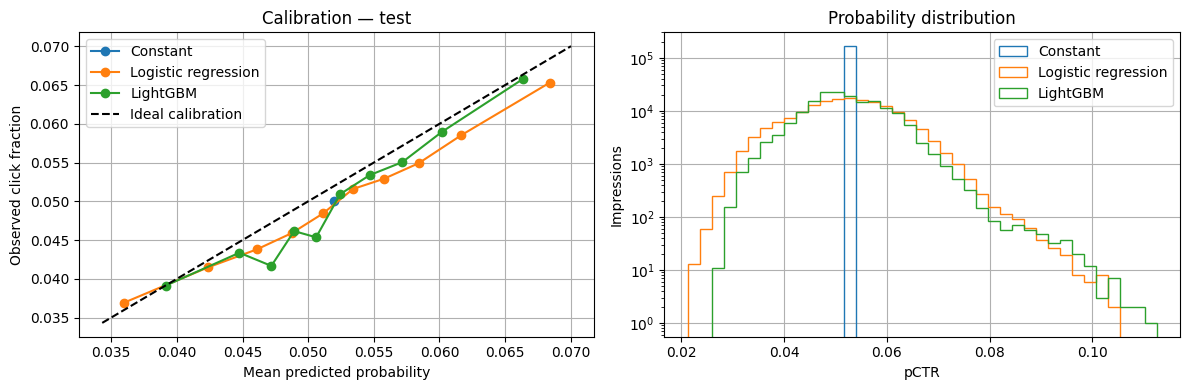

,Mean pCTR,Observed CTR,Brier
model,,,
Constant,0.051972,0.049981,0.047487
Logistic regression,0.052200,0.049981,0.047425
LightGBM,0.052152,0.049981,0.047425


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
cal_rows = []
# Shared bins: a constant score should not artificially widen the axis.
bins = np.linspace(min(p.min() for p in test_prob.values()),
                   max(p.max() for p in test_prob.values()), 40)
for name, p in test_prob.items():
    obs, predicted = calibration_curve(y['test'], p, n_bins=10, strategy='quantile')
    axes[0].plot(predicted, obs, 'o-', label=name)
    axes[1].hist(p, bins=bins, histtype='step', label=name)
    cal_rows.append({'model': name, 'Mean pCTR': p.mean(), 'Observed CTR': y['test'].mean(),
                     'Brier': brier_score_loss(y['test'], p)})
lo, hi = axes[0].get_xlim()
axes[0].plot([max(0, lo), hi], [max(0, lo), hi], 'k--', label='Ideal calibration')
axes[0].set(xlabel='Mean predicted probability', ylabel='Observed click fraction', title='Calibration — test')
axes[1].set(xlabel='pCTR', ylabel='Impressions', title='Probability distribution', yscale='log')
for ax in axes: ax.legend()
plt.tight_layout(); plt.show()
display(pd.DataFrame(cal_rows).set_index('model'))

## 8. Segments: what the average can hide
We inspect the model selected on validation data by placement, missing profile, and ads
seen or unseen in training. IDs are used for this diagnostic, never as predictors.
Small segments have unstable metrics: we show impression and click counts, not just rates.
ROC-AUC is undefined when one class is absent. Differences are associations, not causal effects.
We do not calculate intervals assuming independent impressions: users and ad blocks share context.

,dimension,segment,n,clicks,CTR,pCTR,pCTR-CTR bias,logloss,ROC-AUC
0,pid,430539_1007,61500,3277,0.05328,0.05361,0.00033,0.20736,0.54917
1,pid,430548_1007,103843,4987,0.04802,0.05129,0.00326,0.19225,0.54259
2,profile,missing,10252,525,0.05121,0.05250,0.00129,0.20155,0.55252
3,profile,present,155091,7739,0.04990,0.05213,0.00223,0.19763,0.54694
4,ad,new in sample,40425,1550,0.03834,0.05182,0.01348,0.16395,0.55630
5,ad,seen in train,124918,6714,0.05375,0.05226,-0.00149,0.20885,0.54365


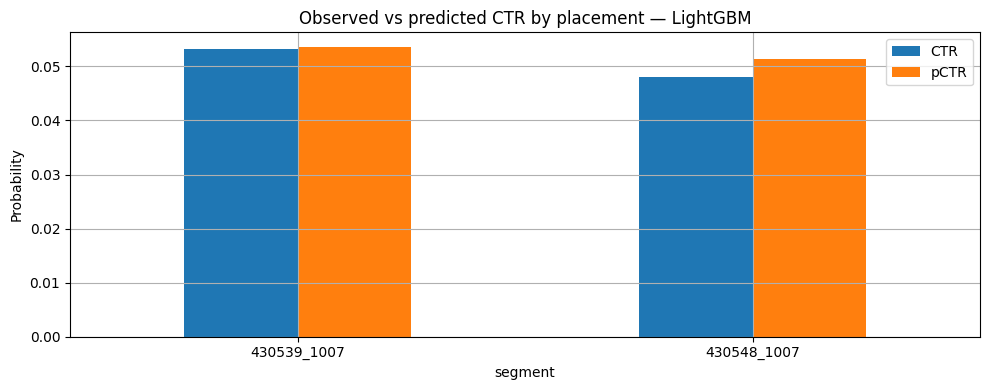

In [9]:
test_rows = df.loc[masks['test'], ['pid', 'adgroup_id', 'cms_group_id', 'clk']].copy()
test_rows['profile'] = np.where(test_rows.cms_group_id.isna(), 'missing', 'present')
test_rows['ad'] = np.where(test_rows.adgroup_id.isin(df.loc[masks['train'], 'adgroup_id']),
                                'seen in train', 'new in sample')
test_rows['p'] = test_prob[best_name]
segments = []
for dimension in ['pid', 'profile', 'ad']:
    for value, group in test_rows.groupby(dimension, observed=True):
        target, p = group.clk.to_numpy(), group.p.to_numpy()
        segments.append({'dimension': dimension, 'segment': value, 'n': len(group),
            'clicks': int(target.sum()), 'CTR': target.mean(), 'pCTR': p.mean(),
            'pCTR-CTR bias': p.mean()-target.mean(), 'logloss': log_loss(target, p, labels=[0, 1]),
            'ROC-AUC': roc_auc_score(target, p) if np.unique(target).size == 2 else np.nan})
segment_table = pd.DataFrame(segments)
display(segment_table.round(5))
placement = segment_table[segment_table['dimension'].eq('pid')].set_index('segment')
placement[['CTR', 'pCTR']].plot.bar(rot=0, title=f'Observed vs predicted CTR by placement — {best_name}')
plt.ylabel('Probability'); plt.tight_layout(); plt.show()

## 9. Interpreting the results and exercises
The next cell summarizes **this run**, rather than copying metrics from the full dataset.
Changing the sample changes the results and the definition of “new” ads.

1. Why does lowering the threshold improve recall but usually reduce precision? Compare both rules.
2. Does the model with the highest ROC-AUC also have the lowest log loss? Explain what each measures.
3. Compare the calibration curve with the bias in each segment. Do errors cancel out in the average?
4. As a new experiment, reserve another temporal partition for calibration. Do not fit on the current test set.
5. Why would using per-ad CTR computed over all eight days cause leakage?
6. Repeat with another seed as a sensitivity analysis, without selecting the seed that performs best on test.

**Scope:** this is a predictive model for ads the historical system chose to show.
It does not establish what would happen under a different serving policy or guarantee increased revenue.
We have not performed an exhaustive search, estimated uncertainty intervals, or evaluated multiple time windows.

In [10]:
baseline_loss = log_loss(y['test'], test_prob['Constant'])
chosen_loss = log_loss(y['test'], test_prob[best_name])
print(f'Model selected without looking at test: {best_name}')
print(f'Test CTR: {y["test"].mean():.2%}; always-no-click accuracy: {1-y["test"].mean():.2%}')
print(f'Test log loss: baseline {baseline_loss:.5f}; selected {chosen_loss:.5f}')
print(f'Relative reduction in log loss: {(baseline_loss-chosen_loss)/baseline_loss:.2%}')
print(f'Test AP: {average_precision_score(y["test"], test_prob[best_name]):.5f}')
print('High baseline accuracy does not mean it identifies clicks: its recall at 0.5 is zero.')
print('Inspect the tables and plots: small overall gains can hide errors within segments.')
print('\nSegment results for the selected model:')
for row in segment_table.itertuples():
    print(f'{row.segment}: CTR {row.CTR:.2%}, pCTR {row.pCTR:.2%}, n={row.n:,}')
print('Log loss across segments with different prevalence does not by itself indicate which is easier to rank.')
print('The validation winner may not win on test: we do not change the selection retrospectively.')


Model selected without looking at test: LightGBM
Test CTR: 5.00%; always-no-click accuracy: 95.00%
Test log loss: baseline 0.19850; selected 0.19787
Relative reduction in log loss: 0.32%
Test AP: 0.05860
High baseline accuracy does not mean it identifies clicks: its recall at 0.5 is zero.
Inspect the tables and plots: small overall gains can hide errors within segments.

Segment results for the selected model:
430539_1007: CTR 5.33%, pCTR 5.36%, n=61,500
430548_1007: CTR 4.80%, pCTR 5.13%, n=103,843
missing: CTR 5.12%, pCTR 5.25%, n=10,252
present: CTR 4.99%, pCTR 5.21%, n=155,091
new in sample: CTR 3.83%, pCTR 5.18%, n=40,425
seen in train: CTR 5.37%, pCTR 5.23%, n=124,918
Log loss across segments with different prevalence does not by itself indicate which is easier to rank.
The validation winner may not win on test: we do not change the selection retrospectively.


### Observations from the saved run (5%, seed 42)

- The baseline achieves **95% accuracy and zero recall** at a threshold of 0.5. This shows why accuracy alone is not enough.
- LightGBM was selected on validation data, but logistic regression has slightly lower test log loss (about 0.19785 versus 0.19787). The difference is small; without uncertainty estimates or multiple time windows, we do not claim general superiority.
- Lowering LightGBM's threshold to about 0.0547 yields 41% recall and 5.9% precision: it detects more clicks at the cost of many false positives. Maximizing F1 is not the same as optimizing business outcomes.
- Mean scores are around 5.22%, versus an observed CTR of 5.00%: a slight overall overestimate. For new ads **in the sample**, pCTR is about 5.18% versus an observed CTR of 3.83%, a much larger error than the average suggests.
- These features improve log loss only slightly over the baseline. This modest gain is a starting point for exploring better features and temporal evaluation.

These numbers describe the saved run, not constants of the dataset. The tables above are recomputed when the configuration changes.